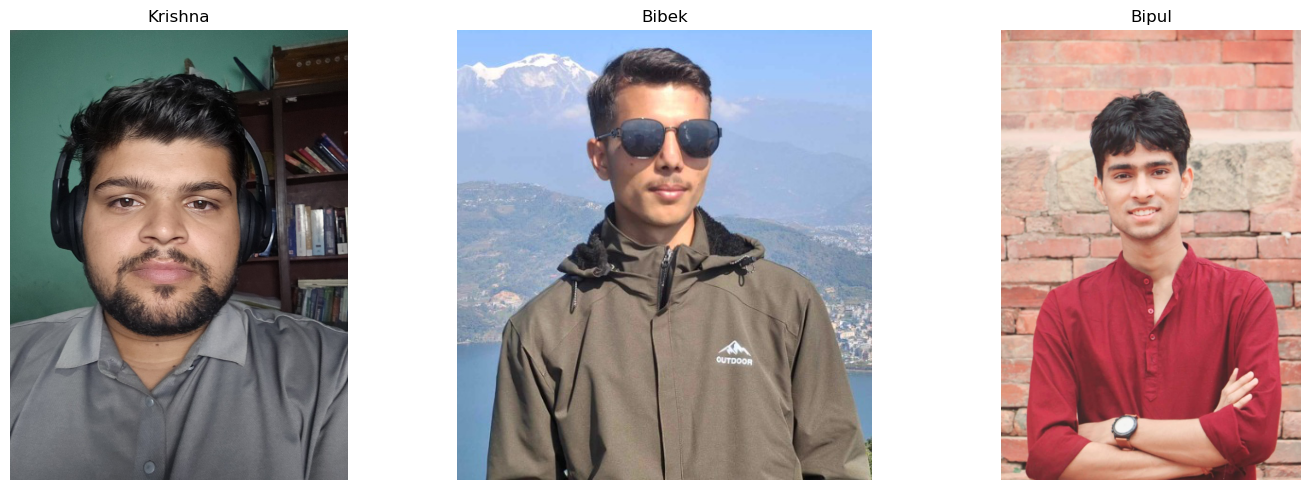

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Define Path to Images - Fix the paths
KRISHNA = 'foto/krishna.jpg'  # or use absolute paths like 'C:/Users/krishna/Programming/_imagelab/foto/krishna.jpg'
BIBEK = 'foto/bibek.jpg'
BIPUL = 'foto/bipul.jpg'

# Load and check if images exist
def load_and_check_image(path):
    img = cv2.imread(path)
    if img is None:
        print(f"Error: Could not load image from {path}")
        return None
    return img

# Load the Images with error checking
img_krishna = load_and_check_image(KRISHNA)
img_bibek = load_and_check_image(BIBEK)
img_bipul = load_and_check_image(BIPUL)

# Only proceed if all images loaded successfully
if img_krishna is not None and img_bibek is not None and img_bipul is not None:
    # Convert images from BGR to RGB for displaying with matplotlib
    img_krishna_rgb = cv2.cvtColor(img_krishna, cv2.COLOR_BGR2RGB)
    img_bibek_rgb = cv2.cvtColor(img_bibek, cv2.COLOR_BGR2RGB)
    img_bipul_rgb = cv2.cvtColor(img_bipul, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_krishna_rgb)
    plt.title("Krishna")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(img_bibek_rgb)
    plt.title("Bibek")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(img_bipul_rgb)
    plt.title("Bipul")
    plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Please ensure the 'foto' folder exists in your workspace with the required images:")
    print("- krishna.jpg")
    print("- bibek.jpg") 
    print("- bipul.jpg")

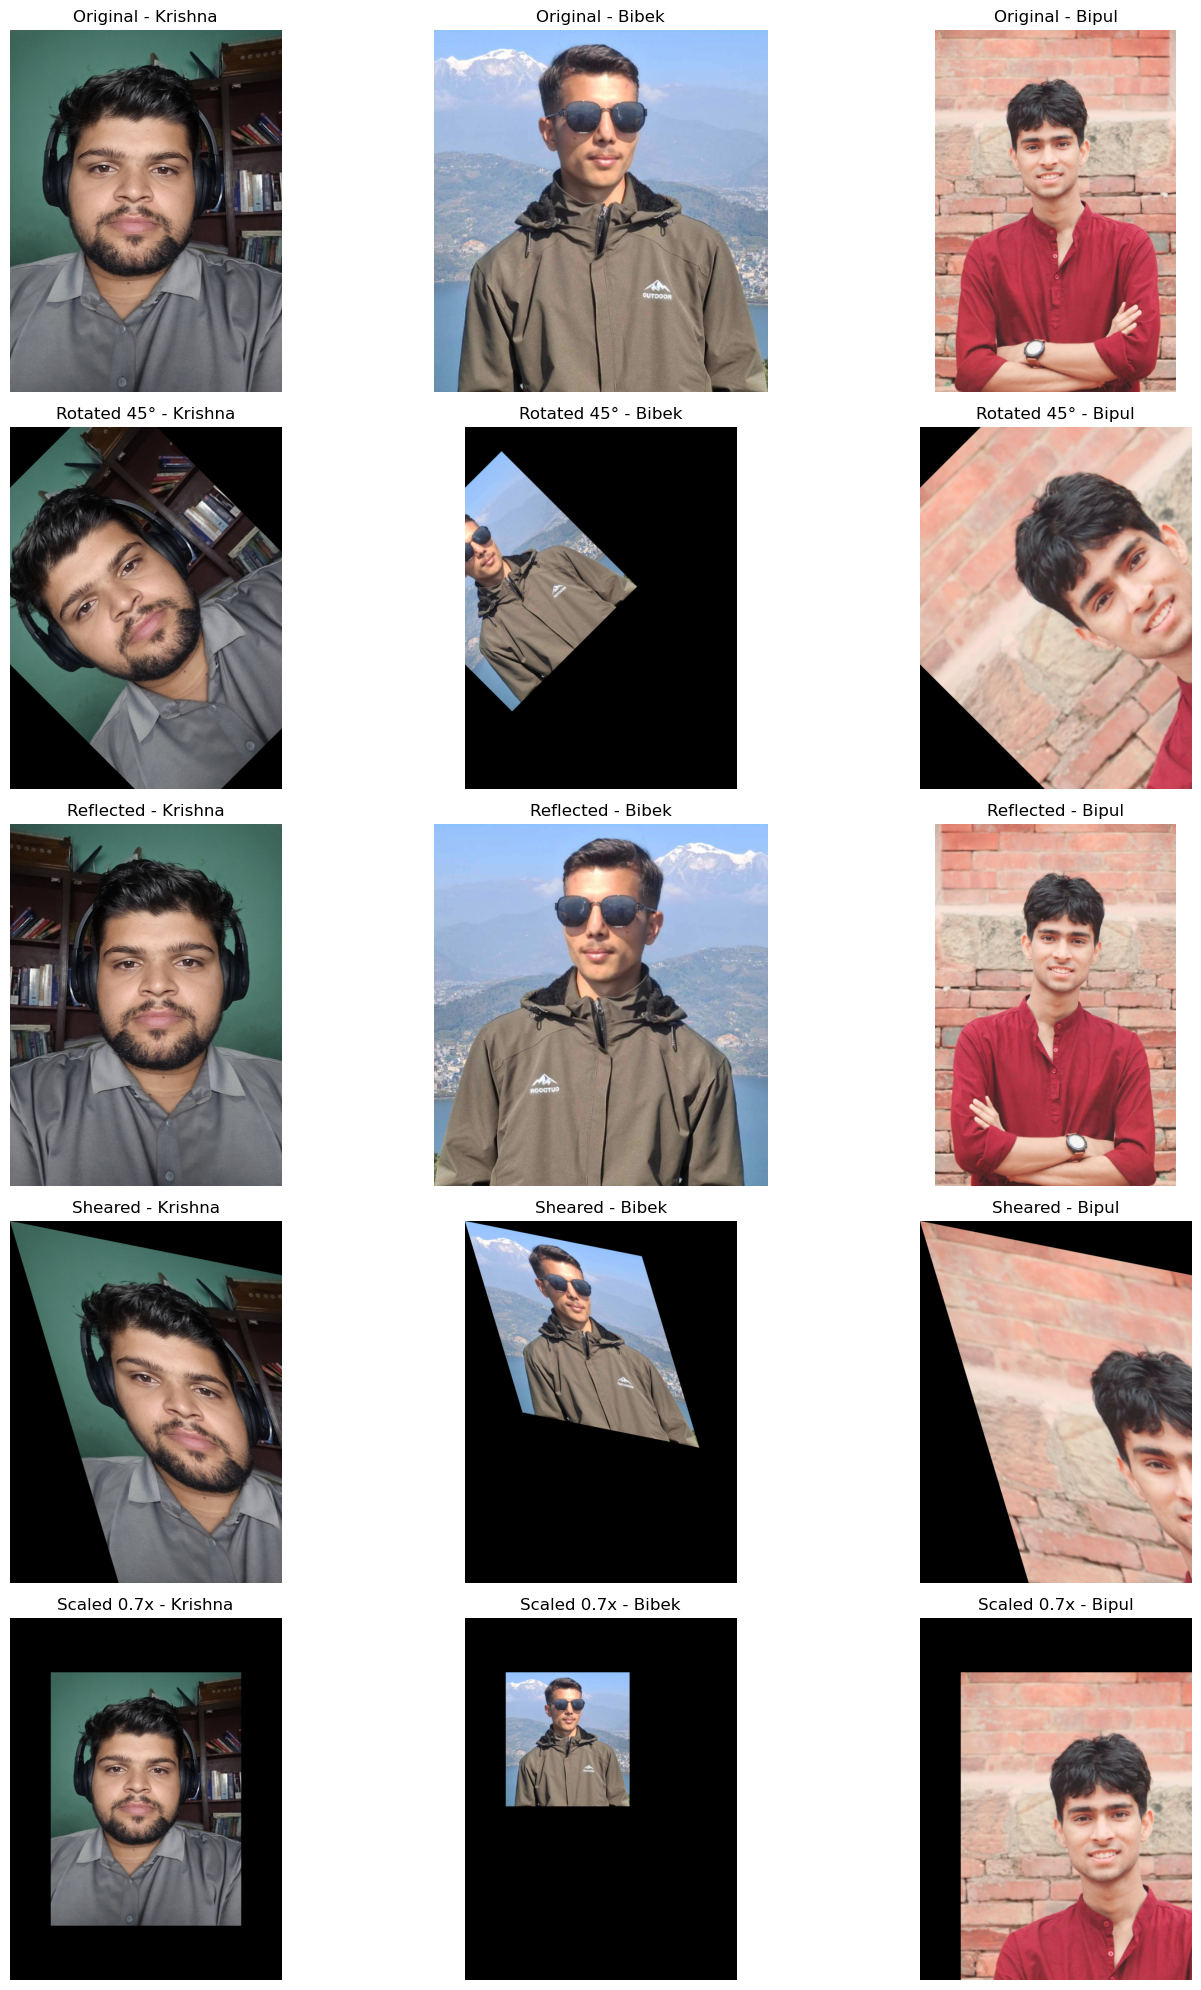

Affine Transformations Applied:
1. Rotation: 45 degrees clockwise
2. Reflection: Horizontal flip
3. Shearing: X-shear=0.3, Y-shear=0.2
4. Scaling: Factor of 0.7 (shrink)


In [6]:
# Apply Affine Transformations on the loaded images
if img_krishna is not None and img_bibek is not None and img_bipul is not None:
    
    # Get image dimensions
    height, width = img_krishna.shape[:2]
    center = (width // 2, height // 2)
    
    # 1. ROTATION - Rotate by 45 degrees
    rotation_matrix = cv2.getRotationMatrix2D(center, 45, 1.0)
    krishna_rotated = cv2.warpAffine(img_krishna, rotation_matrix, (width, height))
    bibek_rotated = cv2.warpAffine(img_bibek, rotation_matrix, (width, height))
    bipul_rotated = cv2.warpAffine(img_bipul, rotation_matrix, (width, height))
    
    # 2. REFLECTION - Horizontal flip
    krishna_reflected = cv2.flip(img_krishna, 1)  # 1 for horizontal flip
    bibek_reflected = cv2.flip(img_bibek, 1)
    bipul_reflected = cv2.flip(img_bipul, 1)
    
    # 3. SHEARING - Shear transformation
    shear_matrix = np.float32([[1, 0.3, 0],    # Shear factor of 0.3
                               [0.2, 1, 0]])    # Shear in both x and y directions
    krishna_sheared = cv2.warpAffine(img_krishna, shear_matrix, (width, height))
    bibek_sheared = cv2.warpAffine(img_bibek, shear_matrix, (width, height))
    bipul_sheared = cv2.warpAffine(img_bipul, shear_matrix, (width, height))
    
    # 4. SCALING - Scale by factor of 0.7 (shrink)
    scale_matrix = cv2.getRotationMatrix2D(center, 0, 0.7)
    krishna_scaled = cv2.warpAffine(img_krishna, scale_matrix, (width, height))
    bibek_scaled = cv2.warpAffine(img_bibek, scale_matrix, (width, height))
    bipul_scaled = cv2.warpAffine(img_bipul, scale_matrix, (width, height))
    
    # Convert all images from BGR to RGB for matplotlib display
    def bgr_to_rgb(img):
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Original images
    krishna_rgb = bgr_to_rgb(img_krishna)
    bibek_rgb = bgr_to_rgb(img_bibek)
    bipul_rgb = bgr_to_rgb(img_bipul)
    
    # Transformed images
    krishna_rot_rgb = bgr_to_rgb(krishna_rotated)
    bibek_rot_rgb = bgr_to_rgb(bibek_rotated)
    bipul_rot_rgb = bgr_to_rgb(bipul_rotated)
    
    krishna_ref_rgb = bgr_to_rgb(krishna_reflected)
    bibek_ref_rgb = bgr_to_rgb(bibek_reflected)
    bipul_ref_rgb = bgr_to_rgb(bipul_reflected)
    
    krishna_shear_rgb = bgr_to_rgb(krishna_sheared)
    bibek_shear_rgb = bgr_to_rgb(bibek_sheared)
    bipul_shear_rgb = bgr_to_rgb(bipul_sheared)
    
    krishna_scale_rgb = bgr_to_rgb(krishna_scaled)
    bibek_scale_rgb = bgr_to_rgb(bibek_scaled)
    bipul_scale_rgb = bgr_to_rgb(bipul_scaled)
    
    # Display all transformations
    fig, axes = plt.subplots(5, 3, figsize=(15, 20))
    
    # Row 1: Original Images
    axes[0, 0].imshow(krishna_rgb)
    axes[0, 0].set_title("Original - Krishna")
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(bibek_rgb)
    axes[0, 1].set_title("Original - Bibek")
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(bipul_rgb)
    axes[0, 2].set_title("Original - Bipul")
    axes[0, 2].axis('off')
    
    # Row 2: Rotation (45 degrees)
    axes[1, 0].imshow(krishna_rot_rgb)
    axes[1, 0].set_title("Rotated 45° - Krishna")
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(bibek_rot_rgb)
    axes[1, 1].set_title("Rotated 45° - Bibek")
    axes[1, 1].axis('off')
    
    axes[1, 2].imshow(bipul_rot_rgb)
    axes[1, 2].set_title("Rotated 45° - Bipul")
    axes[1, 2].axis('off')
    
    # Row 3: Reflection (Horizontal flip)
    axes[2, 0].imshow(krishna_ref_rgb)
    axes[2, 0].set_title("Reflected - Krishna")
    axes[2, 0].axis('off')
    
    axes[2, 1].imshow(bibek_ref_rgb)
    axes[2, 1].set_title("Reflected - Bibek")
    axes[2, 1].axis('off')
    
    axes[2, 2].imshow(bipul_ref_rgb)
    axes[2, 2].set_title("Reflected - Bipul")
    axes[2, 2].axis('off')
    
    # Row 4: Shearing
    axes[3, 0].imshow(krishna_shear_rgb)
    axes[3, 0].set_title("Sheared - Krishna")
    axes[3, 0].axis('off')
    
    axes[3, 1].imshow(bibek_shear_rgb)
    axes[3, 1].set_title("Sheared - Bibek")
    axes[3, 1].axis('off')
    
    axes[3, 2].imshow(bipul_shear_rgb)
    axes[3, 2].set_title("Sheared - Bipul")
    axes[3, 2].axis('off')
    
    # Row 5: Scaling (0.7x)
    axes[4, 0].imshow(krishna_scale_rgb)
    axes[4, 0].set_title("Scaled 0.7x - Krishna")
    axes[4, 0].axis('off')
    
    axes[4, 1].imshow(bibek_scale_rgb)
    axes[4, 1].set_title("Scaled 0.7x - Bibek")
    axes[4, 1].axis('off')
    
    axes[4, 2].imshow(bipul_scale_rgb)
    axes[4, 2].set_title("Scaled 0.7x - Bipul")
    axes[4, 2].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print("Affine Transformations Applied:")
    print("1. Rotation: 45 degrees clockwise")
    print("2. Reflection: Horizontal flip")
    print("3. Shearing: X-shear=0.3, Y-shear=0.2")
    print("4. Scaling: Factor of 0.7 (shrink)")
    
else:
    print("Error: Images not loaded properly. Cannot apply transformations.")

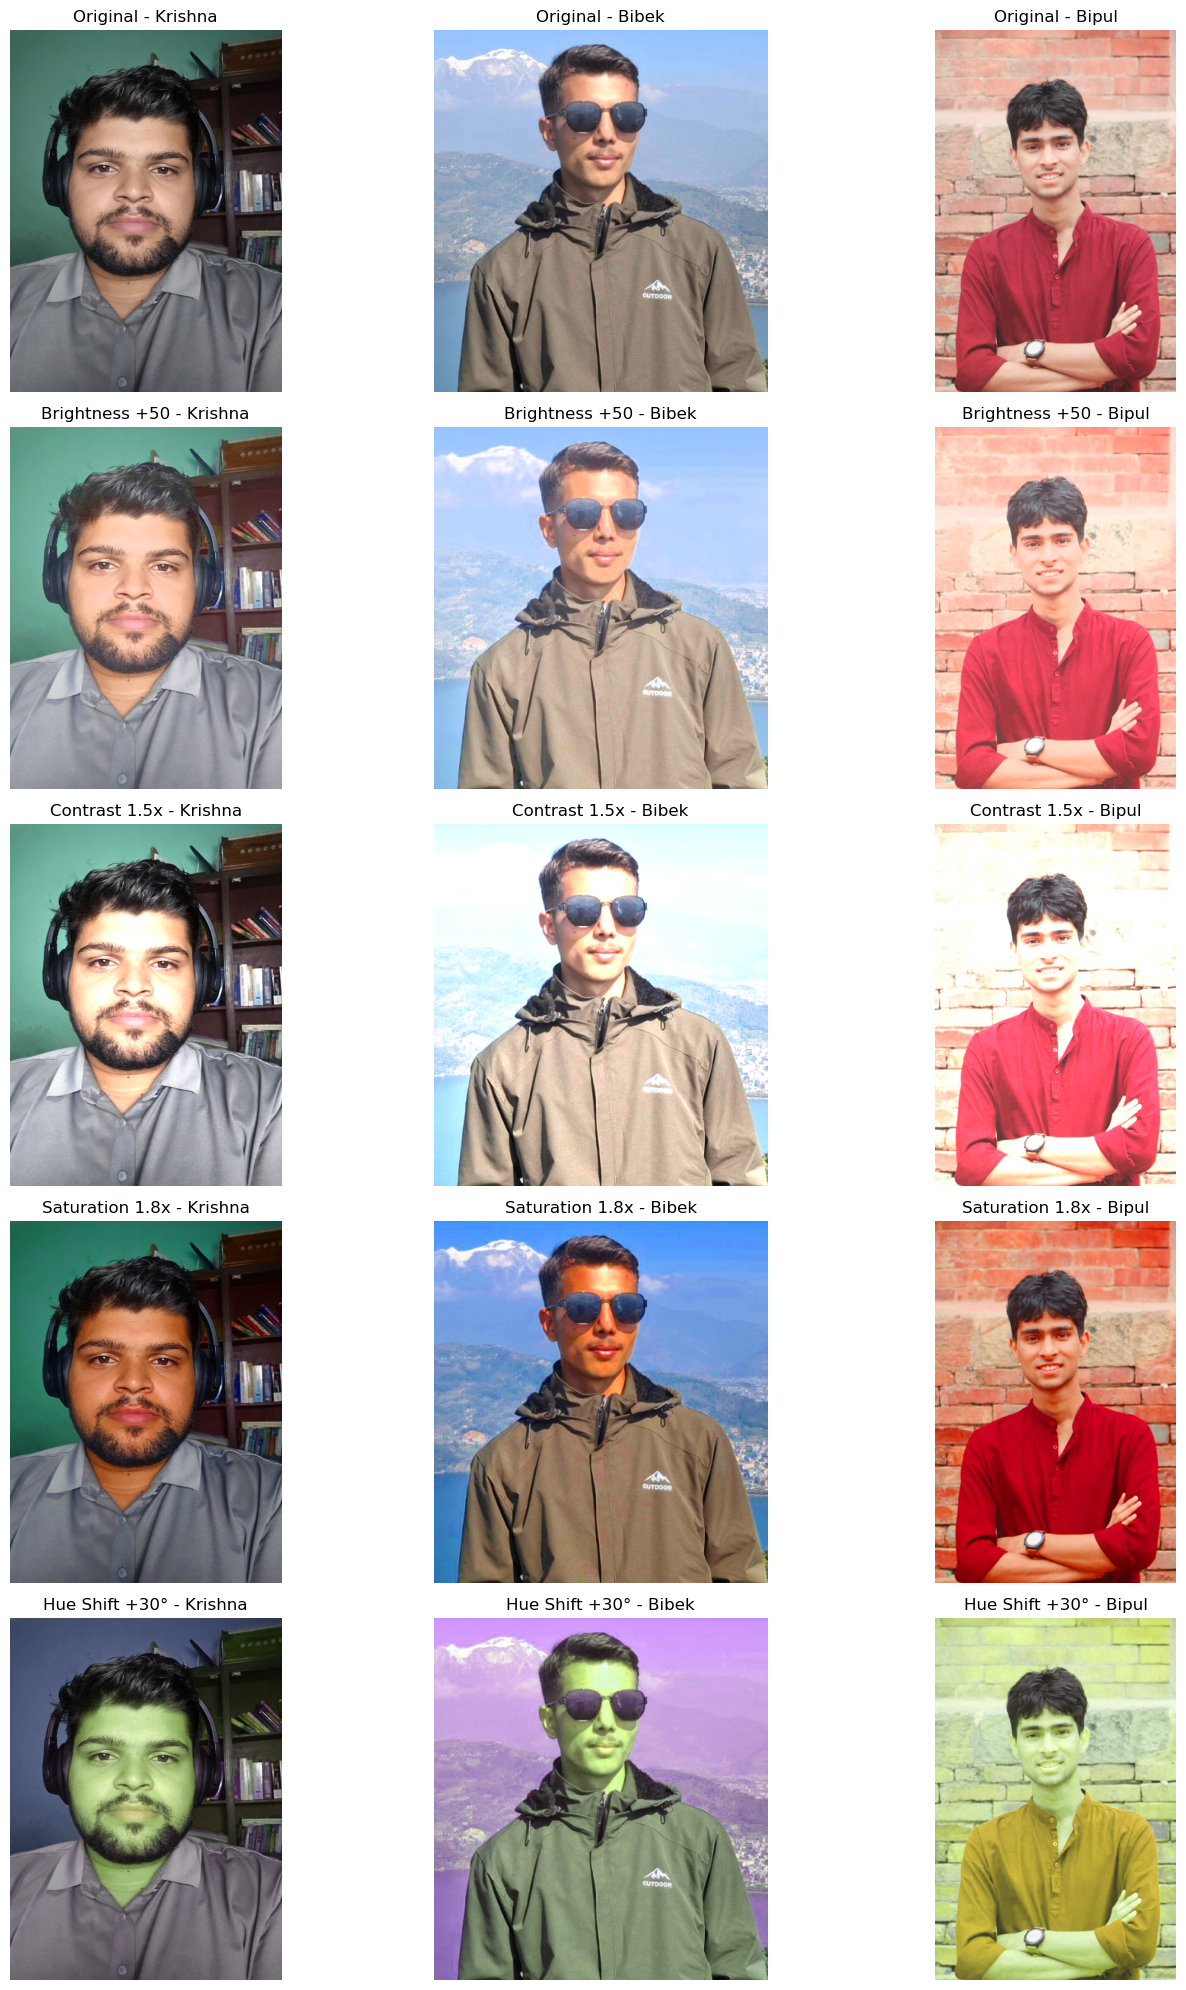

Photometric Augmentations Applied:
1. Brightness: +50 value increase
2. Contrast: 1.5x multiplication factor
3. Saturation: 1.8x increase
4. Hue Shift: +30 degrees rotation


In [8]:
# Photometric Augmentation - Brightness, Contrast, Saturation, Hue adjustments
if img_krishna is not None and img_bibek is not None and img_bipul is not None:
    
    def adjust_brightness(img, value):
        """Adjust brightness by adding a constant value to all pixels"""
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(hsv)
        
        # Add brightness value (can be positive or negative)
        v = cv2.add(v, value)
        
        # Merge channels back
        final_hsv = cv2.merge((h, s, v))
        return cv2.cvtColor(final_hsv, cv2.COLOR_HSV2BGR)
    
    def adjust_contrast(img, alpha):
        """Adjust contrast by multiplying pixel values by alpha factor"""
        # Convert to float to prevent overflow
        img_float = img.astype(np.float64)
        # Apply contrast: new_img = alpha * img + beta (beta=0 for pure contrast)
        adjusted = cv2.convertScaleAbs(img_float * alpha)
        return adjusted
    
    def adjust_saturation(img, saturation_scale):
        """Adjust saturation in HSV color space"""
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(hsv)
        
        # Scale saturation channel
        s = cv2.multiply(s, saturation_scale)
        
        # Merge channels back
        final_hsv = cv2.merge((h, s, v))
        return cv2.cvtColor(final_hsv, cv2.COLOR_HSV2BGR)
    
    def adjust_hue(img, hue_shift):
        """Shift hue by adding a constant value to hue channel"""
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(hsv)
        
        # Add hue shift (OpenCV hue range is 0-179)
        h = cv2.add(h, hue_shift)
        
        # Merge channels back
        final_hsv = cv2.merge((h, s, v))
        return cv2.cvtColor(final_hsv, cv2.COLOR_HSV2BGR)
    
    # Apply photometric augmentations
    # 1. BRIGHTNESS ADJUSTMENT (+50 brightness)
    krishna_bright = adjust_brightness(img_krishna, 50)
    bibek_bright = adjust_brightness(img_bibek, 50)
    bipul_bright = adjust_brightness(img_bipul, 50)
    
    # 2. CONTRAST MANIPULATION (1.5x contrast)
    krishna_contrast = adjust_contrast(img_krishna, 1.5)
    bibek_contrast = adjust_contrast(img_bibek, 1.5)
    bipul_contrast = adjust_contrast(img_bipul, 1.5)
    
    # 3. SATURATION MODIFICATION (1.8x saturation)
    krishna_saturated = adjust_saturation(img_krishna, 1.8)
    bibek_saturated = adjust_saturation(img_bibek, 1.8)
    bipul_saturated = adjust_saturation(img_bipul, 1.8)
    
    # 4. HUE SHIFT (+30 degrees hue shift)
    krishna_hue_shifted = adjust_hue(img_krishna, 30)
    bibek_hue_shifted = adjust_hue(img_bibek, 30)
    bipul_hue_shifted = adjust_hue(img_bipul, 30)
    
    # Convert all images from BGR to RGB for matplotlib display
    def bgr_to_rgb(img):
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Original images
    krishna_rgb = bgr_to_rgb(img_krishna)
    bibek_rgb = bgr_to_rgb(img_bibek)
    bipul_rgb = bgr_to_rgb(img_bipul)
    
    # Photometric augmented images
    krishna_bright_rgb = bgr_to_rgb(krishna_bright)
    bibek_bright_rgb = bgr_to_rgb(bibek_bright)
    bipul_bright_rgb = bgr_to_rgb(bipul_bright)
    
    krishna_contrast_rgb = bgr_to_rgb(krishna_contrast)
    bibek_contrast_rgb = bgr_to_rgb(bibek_contrast)
    bipul_contrast_rgb = bgr_to_rgb(bipul_contrast)
    
    krishna_sat_rgb = bgr_to_rgb(krishna_saturated)
    bibek_sat_rgb = bgr_to_rgb(bibek_saturated)
    bipul_sat_rgb = bgr_to_rgb(bipul_saturated)
    
    krishna_hue_rgb = bgr_to_rgb(krishna_hue_shifted)
    bibek_hue_rgb = bgr_to_rgb(bibek_hue_shifted)
    bipul_hue_rgb = bgr_to_rgb(bipul_hue_shifted)
    
    # Display all photometric augmentations
    fig, axes = plt.subplots(5, 3, figsize=(15, 20))
    
    # Row 1: Original Images
    axes[0, 0].imshow(krishna_rgb)
    axes[0, 0].set_title("Original - Krishna")
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(bibek_rgb)
    axes[0, 1].set_title("Original - Bibek")
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(bipul_rgb)
    axes[0, 2].set_title("Original - Bipul")
    axes[0, 2].axis('off')
    
    # Row 2: Brightness Adjustment (+50)
    axes[1, 0].imshow(krishna_bright_rgb)
    axes[1, 0].set_title("Brightness +50 - Krishna")
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(bibek_bright_rgb)
    axes[1, 1].set_title("Brightness +50 - Bibek")
    axes[1, 1].axis('off')
    
    axes[1, 2].imshow(bipul_bright_rgb)
    axes[1, 2].set_title("Brightness +50 - Bipul")
    axes[1, 2].axis('off')
    
    # Row 3: Contrast Manipulation (1.5x)
    axes[2, 0].imshow(krishna_contrast_rgb)
    axes[2, 0].set_title("Contrast 1.5x - Krishna")
    axes[2, 0].axis('off')
    
    axes[2, 1].imshow(bibek_contrast_rgb)
    axes[2, 1].set_title("Contrast 1.5x - Bibek")
    axes[2, 1].axis('off')
    
    axes[2, 2].imshow(bipul_contrast_rgb)
    axes[2, 2].set_title("Contrast 1.5x - Bipul")
    axes[2, 2].axis('off')
    
    # Row 4: Saturation Modification (1.8x)
    axes[3, 0].imshow(krishna_sat_rgb)
    axes[3, 0].set_title("Saturation 1.8x - Krishna")
    axes[3, 0].axis('off')
    
    axes[3, 1].imshow(bibek_sat_rgb)
    axes[3, 1].set_title("Saturation 1.8x - Bibek")
    axes[3, 1].axis('off')
    
    axes[3, 2].imshow(bipul_sat_rgb)
    axes[3, 2].set_title("Saturation 1.8x - Bipul")
    axes[3, 2].axis('off')
    
    # Row 5: Hue Shift (+30 degrees)
    axes[4, 0].imshow(krishna_hue_rgb)
    axes[4, 0].set_title("Hue Shift +30° - Krishna")
    axes[4, 0].axis('off')
    
    axes[4, 1].imshow(bibek_hue_rgb)
    axes[4, 1].set_title("Hue Shift +30° - Bibek")
    axes[4, 1].axis('off')
    
    axes[4, 2].imshow(bipul_hue_rgb)
    axes[4, 2].set_title("Hue Shift +30° - Bipul")
    axes[4, 2].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print("Photometric Augmentations Applied:")
    print("1. Brightness: +50 value increase")
    print("2. Contrast: 1.5x multiplication factor")
    print("3. Saturation: 1.8x increase")
    print("4. Hue Shift: +30 degrees rotation")
    
else:
    print("Error: Images not loaded properly. Cannot apply photometric augmentations.")